# Лабораторная работа №1: регрессия

**Задача:** предсказать экспертную оценку качества вина `quality` (0–10) по физико-химическим свойствам.
Датасет — [Wine Quality (UCI)](https://archive.ics.uci.edu/dataset/186/wine+quality): красные и белые вина «Vinho Verde».

**Основная метрика:** RMSE (порог: RMSE < 0.70), дополнительная — MAE.

План работы:
1. Знакомство с данными (EDA) и выводы.
2. Разбиение на train / test.
3. Baseline — константное предсказание.
4. Метрики: MAE и RMSE.
5. Модели: линейная регрессия, Random Forest, Gradient Boosting.
6. Честное сравнение моделей, итоговая таблица.
7. Feature importance.
8. Анализ ошибок лучшей модели.

In [1]:
import warnings
warnings.simplefilter("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

%matplotlib inline
sns.set(style="darkgrid")
pd.set_option("display.precision", 4)

RANDOM_STATE = 42

# 1. Знакомство с данными

Данные лежат в двух файлах: красные (`winequality-red.csv`) и белые (`winequality-white.csv`) вина. Разделитель — `;`.
Объединим их в один датасет и добавим бинарный признак `is_red`, чтобы модель могла учитывать тип вина:
у красных и белых вин сильно различаются распределения признаков (сахар, диоксид серы, кислотность),
а одна общая модель обучается на большем числе объектов.

In [2]:
red = pd.read_csv("wine+quality/winequality-red.csv", sep=";")
white = pd.read_csv("wine+quality/winequality-white.csv", sep=";")
red["is_red"] = 1
white["is_red"] = 0

df = pd.concat([red, white], ignore_index=True)
TARGET = "quality"
FEATURES = [c for c in df.columns if c != TARGET]

print("Красных:", len(red), " Белых:", len(white), " Всего:", df.shape)
df.head()

Красных: 1599  Белых: 4898  Всего: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  is_red                6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


In [4]:
print("Пропусков:", df.isna().sum().sum())
print("Полных дубликатов строк:", df.duplicated().sum())
df.describe().T

Пропусков: 0
Полных дубликатов строк: 1177


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.2153,1.2964,3.8000,6.4000,7.0000,7.700,15.900
volatile acidity,6497.0,0.3397,0.1646,0.0800,0.2300,0.2900,0.400,1.580
citric acid,6497.0,0.3186,0.1453,0.0000,0.2500,0.3100,0.390,1.660
residual sugar,6497.0,5.4432,4.7578,0.6000,1.8000,3.0000,8.100,65.800
chlorides,6497.0,0.0560,0.0350,0.0090,0.0380,0.0470,0.065,0.611
free sulfur dioxide,6497.0,30.5253,17.7494,1.0000,17.0000,29.0000,41.000,289.000
total sulfur dioxide,6497.0,115.7446,56.5219,6.0000,77.0000,118.0000,156.000,440.000
density,6497.0,0.9947,0.0030,0.9871,0.9923,0.9949,0.997,1.039
pH,6497.0,3.2185,0.1608,2.7200,3.1100,3.2100,3.320,4.010
sulphates,6497.0,0.5313,0.1488,0.2200,0.4300,0.5100,0.600,2.000


**Первые наблюдения:**
- 6497 объектов, 11 числовых физико-химических признаков + `is_red`. Пропусков нет, все признаки числовые, поэтому кодирование и заполнение пропусков не нужны.
- Признаки измерены в очень разных масштабах: `density` ≈ 1 с разбросом в тысячных долях, а `total sulfur dioxide` — десятки–сотни единиц. Это важно для линейной модели: сравнивать её коэффициенты без масштабирования некорректно.
- У ряда признаков (`residual sugar`, `chlorides`, `free/total sulfur dioxide`) максимум сильно больше 75-го перцентиля, то есть есть длинные правые хвосты и выбросы.
- Около 18% строк — полные дубликаты. Скорее всего, это разные вина с одинаковыми результатами анализов (или повторные записи). Мы их оставляем, потому что скрытая тестовая выборка взята из того же распределения, но помним, что из-за дубликатов оценки качества на test могут получиться немного оптимистичными.

## Целевая переменная

quality
3    0.005
4    0.033
5    0.329
6    0.437
7    0.166
8    0.030
9    0.001
Name: count, dtype: float64
mean = 5.818, median = 6.0, std = 0.873


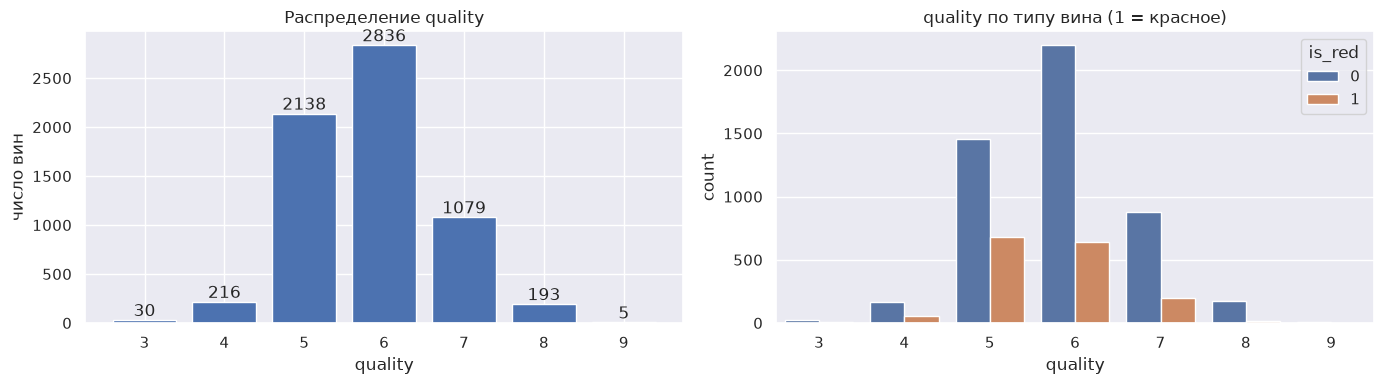

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
counts = df[TARGET].value_counts().sort_index()
axs[0].bar(counts.index, counts.values)
for q, c in counts.items():
    axs[0].text(q, c, str(c), ha="center", va="bottom")
axs[0].set_xlabel("quality"); axs[0].set_ylabel("число вин"); axs[0].set_title("Распределение quality")

sns.countplot(data=df, x=TARGET, hue="is_red", ax=axs[1])
axs[1].set_title("quality по типу вина (1 = красное)")
plt.tight_layout()

print((counts / len(df)).round(3))
print("mean = %.3f, median = %.1f, std = %.3f" % (df[TARGET].mean(), df[TARGET].median(), df[TARGET].std()))

**Вывод по целевой переменной:**
- `quality` принимает целые значения 3–9, хотя шкала 0–10. Распределение сильно несбалансировано: ~77% вин имеют оценку 5 или 6, а оценок 3 и 9 всего 30 и 5.
- Поэтому любая модель, минимизирующая MSE, будет «тянуть» предсказания к центру (5–6): ошибиться на редком очень плохом или отличном вине обходится в сумме дешевле, чем систематически ошибаться на массовых средних винах. Стоит ожидать, что крайние классы будут предсказываться хуже всего (это проверим в анализе ошибок).
- Стандартное отклонение quality ≈ 0.87, и это примерно RMSE константного предсказания средним. Порог 0.70 означает, что модель должна объяснить заметную часть дисперсии, а не просто угадывать среднее.
- Мы решаем задачу как **регрессию**: оценки упорядочены, и ошибка 6→8 хуже ошибки 6→7, что RMSE корректно учитывает.

## Распределения признаков

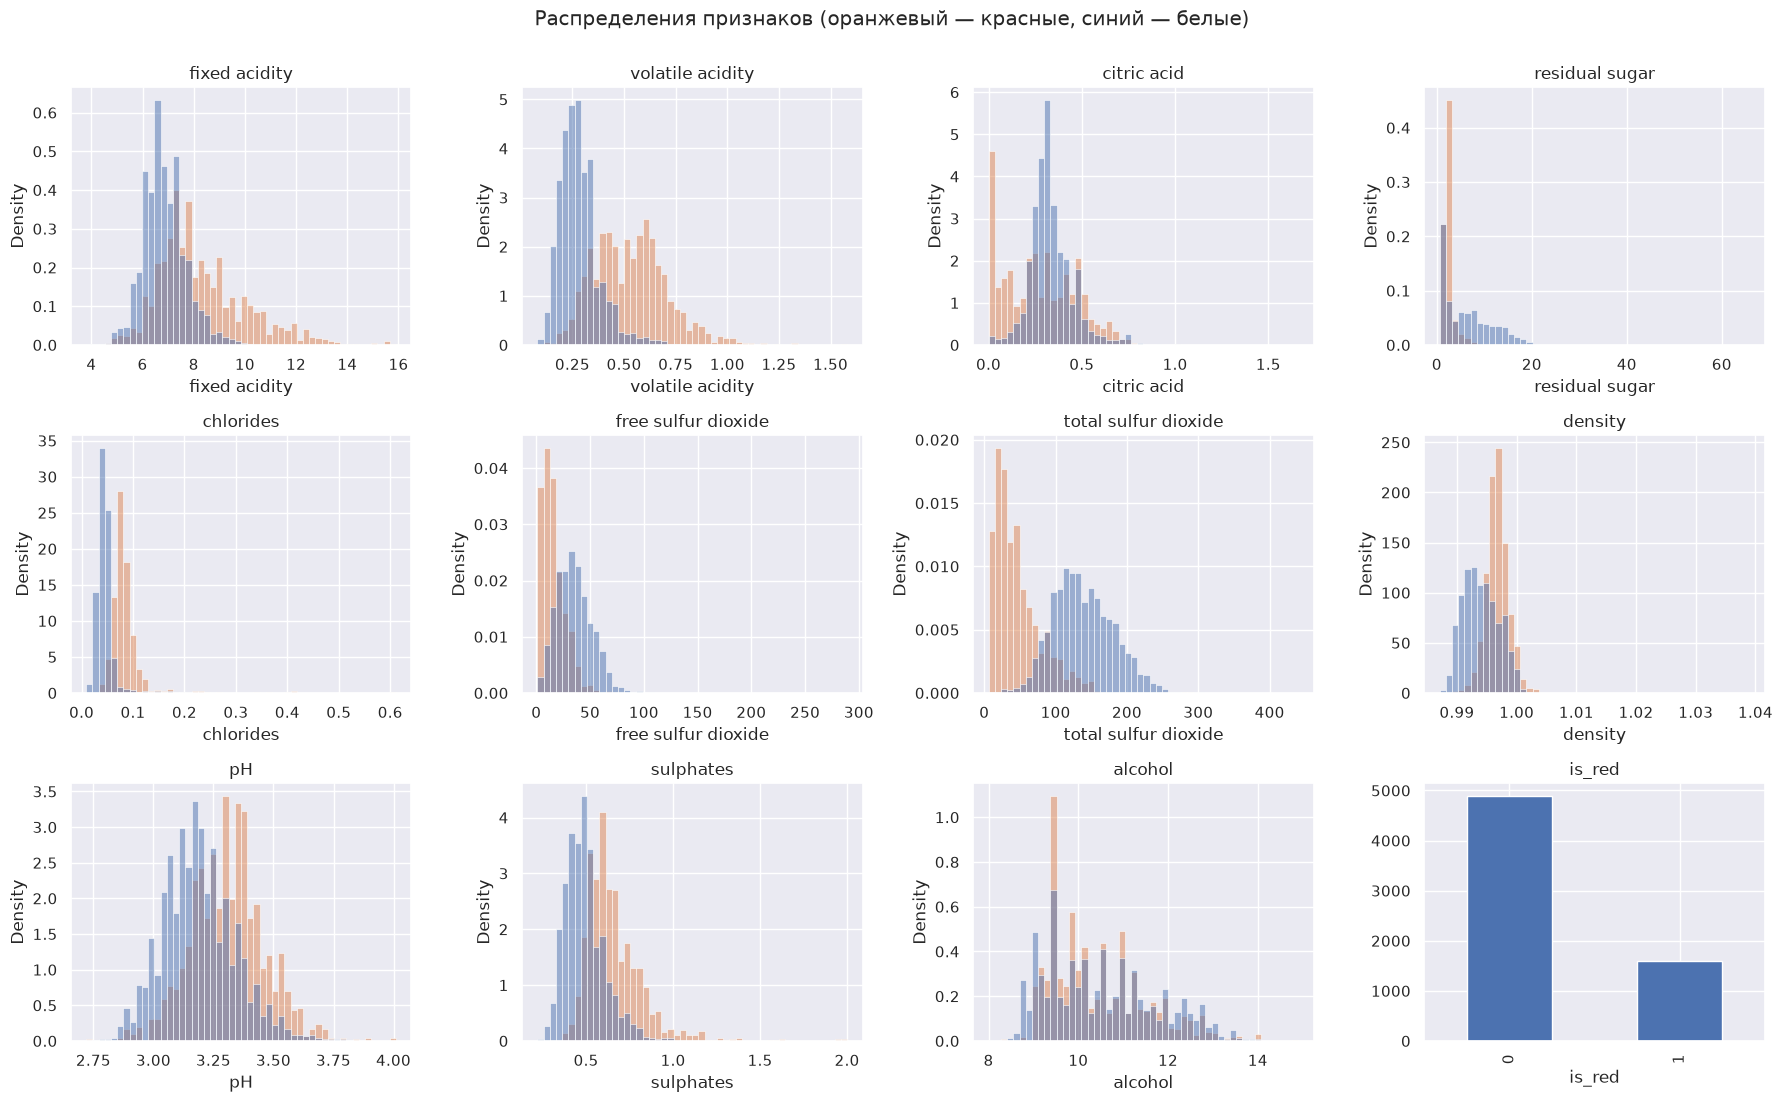

In [6]:
fig, axs = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axs.ravel(), FEATURES):
    if col == "is_red":
        df[col].value_counts().plot.bar(ax=ax); ax.set_title(col); continue
    sns.histplot(data=df, x=col, hue="is_red", bins=50, stat="density", common_norm=False, ax=ax, legend=False)
    ax.set_title(col)
plt.suptitle("Распределения признаков (оранжевый — красные, синий — белые)", y=1.0)
plt.tight_layout()

**Вывод:** распределения признаков у красных и белых вин сильно различаются: у белых гораздо больше `residual sugar` и `total sulfur dioxide`, у красных — выше `volatile acidity`, `chlorides`, `fixed acidity`, `sulphates`. Значит, тип вина — важный контекст: например, «высокий» уровень диоксида серы для красного вина является нормой для белого. Признак `is_red` нужен, а нелинейные модели смогут учесть взаимодействие «тип × признак», чего обычная линейная регрессия не умеет.

## Связь признаков с качеством

alcohol                 0.4443
density                -0.3059
volatile acidity       -0.2657
chlorides              -0.2007
is_red                 -0.1193
citric acid             0.0855
fixed acidity          -0.0767
free sulfur dioxide     0.0555
total sulfur dioxide   -0.0414
sulphates               0.0385
residual sugar         -0.0370
pH                      0.0195
Name: quality, dtype: float64

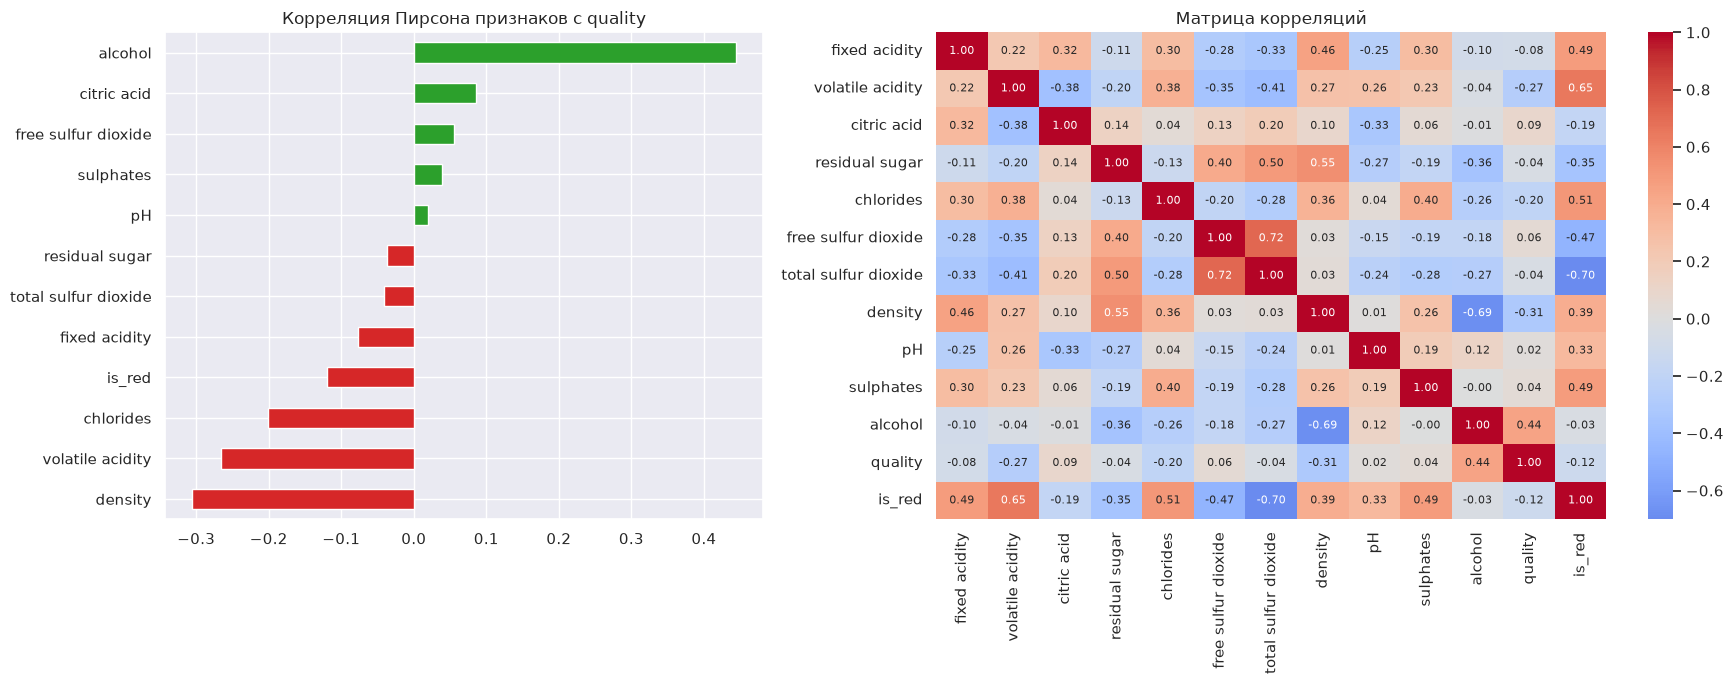

In [7]:
corr = df.corr()
target_corr = corr[TARGET].drop(TARGET).sort_values()

fig, axs = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1, 1.4]})
target_corr.plot.barh(ax=axs[0], color=["tab:red" if v < 0 else "tab:green" for v in target_corr])
axs[0].set_title("Корреляция Пирсона признаков с quality")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axs[1], annot_kws={"size": 8})
axs[1].set_title("Матрица корреляций")
plt.tight_layout()
target_corr.sort_values(key=abs, ascending=False)

In [8]:
# Корреляция Спирмена устойчива к выбросам и улавливает монотонные нелинейные связи
spearman = df.corr(method="spearman")[TARGET].drop(TARGET)
pd.DataFrame({"pearson": corr[TARGET].drop(TARGET), "spearman": spearman}).sort_values("pearson", key=abs, ascending=False)

,pearson,spearman
alcohol,0.4443,0.4469
density,-0.3059,-0.3228
volatile acidity,-0.2657,-0.2578
chlorides,-0.2007,-0.2951
is_red,-0.1193,-0.1230
citric acid,0.0855,0.1057
fixed acidity,-0.0767,-0.0982
free sulfur dioxide,0.0555,0.0869
total sulfur dioxide,-0.0414,-0.0548
sulphates,0.0385,0.0298


In [9]:
# Корреляции с quality отдельно для красных и белых
pd.DataFrame({
    "red": red.drop(columns="is_red").corr()[TARGET].drop(TARGET),
    "white": white.drop(columns="is_red").corr()[TARGET].drop(TARGET),
}).sort_values("red", key=abs, ascending=False)

,red,white
alcohol,0.4762,0.4356
volatile acidity,-0.3906,-0.1947
sulphates,0.2514,0.0537
citric acid,0.2264,-0.0092
total sulfur dioxide,-0.1851,-0.1747
density,-0.1749,-0.3071
chlorides,-0.1289,-0.2099
fixed acidity,0.1241,-0.1137
pH,-0.0577,0.0994
free sulfur dioxide,-0.0507,0.0082


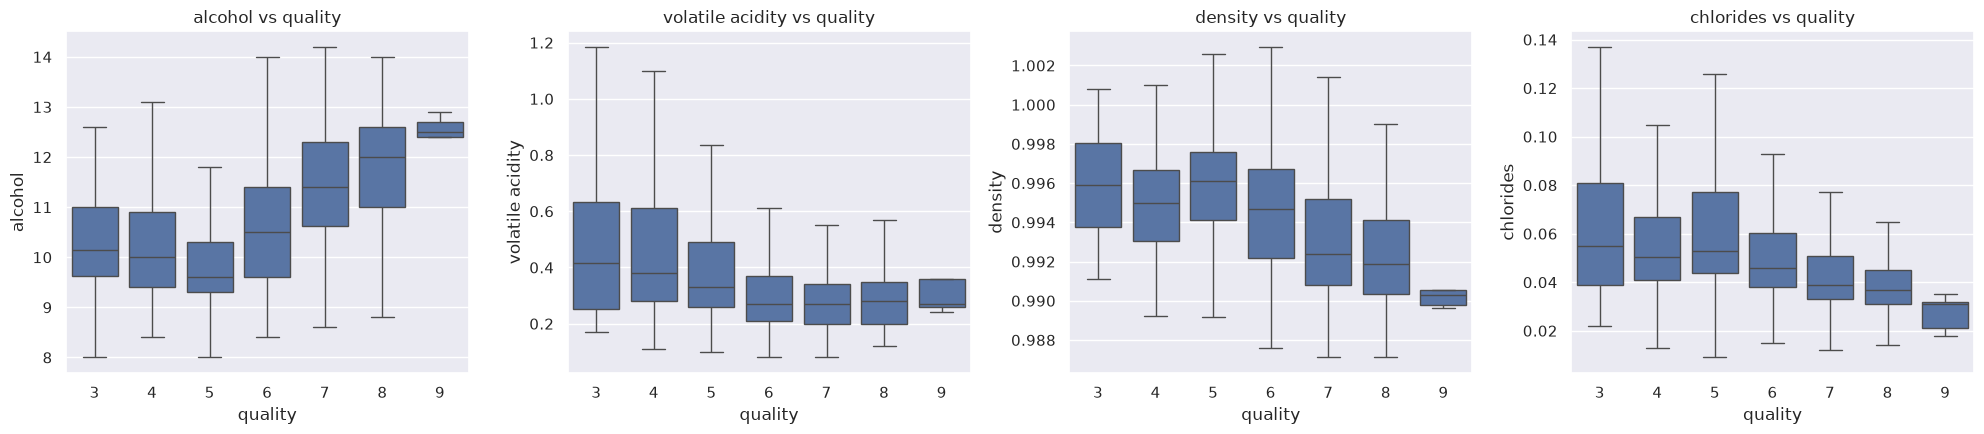

In [10]:
fig, axs = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, col in zip(axs, ["alcohol", "volatile acidity", "density", "chlorides"]):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax, showfliers=False)
    ax.set_title(f"{col} vs quality")
plt.tight_layout()

**Выводы по связи признаков с quality:**

- **`alcohol` — самый сильный признак** (r ≈ 0.44, у Спирмена так же). На boxplot медиана алкоголя монотонно растёт с 5-го класса до 9-го: вина с высоким содержанием спирта эксперты систематически оценивают выше. Для моделирования это главный кандидат в важные признаки, и линейная модель должна его хорошо «поймать». Но связь не совсем линейна: у классов 3–5 уровень алкоголя почти одинаковый, так что нелинейные модели могут извлечь из него больше.
- **`density` (r ≈ −0.31)** — сильная отрицательная связь, но в основном *косвенная*: плотность почти линейно определяется алкоголем (r(density, alcohol) ≈ −0.69, спирт легче воды) и сахаром (r ≈ 0.55). Поэтому density почти не несёт информации сверх alcohol + residual sugar. В линейной модели такая мультиколлинеарность делает коэффициенты неустойчивыми, и интерпретировать вес density отдельно нельзя.
- **`volatile acidity` (r ≈ −0.27)** — летучая кислотность (уксусная кислота) даёт неприятный «уксусный» тон. Для красных вин это второй по силе признак (r ≈ −0.39), для белых он слабее. Признак полезный, причём его влияние зависит от типа вина.
- **`chlorides` (r ≈ −0.20)** — больше солей связано с более низкой оценкой. Распределение сильно скошено, а Спирмен (≈ −0.30) показывает связь сильнее Пирсона, то есть связь монотонная, но нелинейная или искажённая выбросами.
- **Остальные признаки** (`pH`, `residual sugar`, `sulphates`, `total sulfur dioxide`, `citric acid`) по корреляции с quality на всём датасете почти не связаны (|r| < 0.1). Но это не значит, что они бесполезны: например, `sulphates` для красных вин даёт r ≈ 0.25, а для белых ≈ 0.05. На общем датасете эффекты разных типов вин частично гасят друг друга. Деревья могут использовать такие условные зависимости.
- **Сильно коррелированы между собой:** `free` и `total sulfur dioxide` (≈0.72), `density`–`alcohol`, `density`–`residual sugar`, `is_red`–`total sulfur dioxide` (≈ −0.70). Из-за этого важность «размазывается» по коррелированным признакам, и выводы о важности отдельного признака надо делать осторожно.

**Итог EDA:** в данных нет одного доминирующего признака (максимальная |r| = 0.44), связи слабые и частично нелинейные, есть взаимодействия с типом вина. Поэтому линейная регрессия, вероятно, улучшит baseline, но лишь умеренно, а ансамбли деревьев должны дать ощутимый выигрыш. Признаки удалять не будем: их всего 12, а деревьям коррелированные признаки не мешают.

# 2. Подготовка выборок

- **Размер:** 80% train (5197 объектов) / 20% test (1300 объектов). Данных немного (6.5 тыс.), поэтому большую часть оставляем на обучение, а 1300 объектов в тесте достаточно для стабильной оценки RMSE.
- **Способ:** случайное разбиение со **стратификацией по `quality`**. Классы сильно несбалансированы (оценок 9 всего 5 штук, оценок 3 — 30), и при обычном случайном разбиении редкие оценки могут почти целиком попасть в одну из частей. Стратификация сохраняет доли всех оценок в train и test одинаковыми, поэтому оценка на тесте честнее отражает реальное распределение. Временной структуры в данных нет, так что случайное разбиение корректно.
- **`random_state=42`** зафиксирован для воспроизводимости.
- **Тест используется только один раз — для финальной оценки.** Все решения (гиперпараметры, выбор моделей) принимаем по **кросс-валидации на train** (5-fold).

**Почему нельзя многократно оценивать модели на одной и той же тестовой выборке?** Каждый раз, когда мы смотрим на тестовый результат и меняем по нему модель (признаки, гиперпараметры, выбор алгоритма), информация из теста «протекает» в решения. В итоге мы подгоняем модель под конкретные 1300 объектов, включая их шум, то есть **переобучаемся на тест**. Тестовая метрика становится оптимистично смещённой и перестаёт быть оценкой качества на новых данных: на скрытой выборке результат окажется хуже. Кроме того, при переборе многих вариантов лучший из них может победить просто случайно. Для подбора нужны валидационная выборка или кросс-валидация.

In [11]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("train:", X_train.shape, " test:", X_test.shape)
pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index(),
}).round(4)

train: (5197, 12)  test: (1300, 12)


,train,test
quality,,
3,0.0046,0.0046
4,0.0333,0.0331
5,0.3290,0.3292
6,0.4366,0.4362
7,0.1661,0.1662
8,0.0296,0.0300
9,0.0008,0.0008


In [12]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_rmse(model):
    # Средний RMSE на 5-fold кросс-валидации по train (тест не используется)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    return -scores.mean(), scores.std()

results = {}

def evaluate(name, y_pred):
    # Финальная оценка на тестовой выборке — одна и та же для всех моделей
    results[name] = {
        "RMSE": root_mean_squared_error(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
    }
    print(f"{name}: RMSE = {results[name]['RMSE']:.4f}, MAE = {results[name]['MAE']:.4f}")

# 3. Метрики

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^n |y_i - \hat y_i|, \qquad \text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^n (y_i - \hat y_i)^2}$$

- **Что показывает MAE:** среднюю абсолютную величину ошибки в единицах целевой переменной. MAE = 0.45 означает, что в среднем модель ошибается на 0.45 балла. Все ошибки входят линейно, с одинаковым весом.
- **Что показывает RMSE:** корень из среднего квадрата ошибки, тоже в баллах quality. Это «типичная» ошибка, в которой крупные промахи имеют повышенный вес. RMSE — это стандартное отклонение остатков (при нулевой средней ошибке).
- **Почему RMSE сильнее реагирует на большие ошибки:** ошибки возводятся в квадрат до усреднения. Ошибка 2 балла даёт вклад 4, а четыре ошибки по 0.5 вместе дают только 1. Одна грубая ошибка весит больше, чем много мелких такой же суммарной величины.
- **Почему MAE и RMSE могут заметно различаться:** всегда RMSE ≥ MAE, и разрыв тем больше, чем неоднороднее ошибки. Если все ошибки одинаковы по модулю, RMSE = MAE. Если большинство ошибок маленькие, но есть несколько крупных (у нас это редкие вина с оценками 3, 4, 8, 9), RMSE заметно вырастет, а MAE почти нет. Отношение RMSE/MAE — индикатор «тяжёлых хвостов» ошибок.

# 4. Baseline

Baseline — одна константа для всех объектов. Константа, минимизирующая **MSE (а значит и RMSE)**, — это **среднее** целевой переменной на train (для MAE оптимальна медиана). Поскольку основная метрика — RMSE, берём среднее. Для сравнения посчитаем и медиану.
Константу считаем **только по train**.

In [13]:
const_mean = y_train.mean()
const_median = y_train.median()
print(f"Среднее quality на train = {const_mean:.4f}, медиана = {const_median}")

evaluate("Baseline (mean)", np.full(len(y_test), const_mean))
print(f"(для сравнения, константа-медиана: RMSE = {root_mean_squared_error(y_test, np.full(len(y_test), const_median)):.4f}, "
      f"MAE = {mean_absolute_error(y_test, np.full(len(y_test), const_median)):.4f})")

Среднее quality на train = 5.8182, медиана = 6.0
Baseline (mean): RMSE = 0.8738, MAE = 0.6861
(для сравнения, константа-медиана: RMSE = 0.8923, MAE = 0.6377)


**Вывод:** константа-среднее даёт RMSE ≈ 0.87, что практически совпадает со стандартным отклонением quality. Это «нулевой уровень»: модель, не извлекающая из признаков никакой информации, получит примерно столько. Медиана (6) даёт лучший MAE, но худший RMSE, и это соответствует теории: среднее оптимально для квадратичной ошибки, медиана — для абсолютной. Любая модель должна быть заметно лучше 0.87, а для порога задания нужно < 0.70, то есть снизить ошибку примерно на 20%.

# 5. Модели

## 5.1 Линейная регрессия

Обучим `LinearRegression` внутри `Pipeline` со `StandardScaler`.

**Нужно ли масштабирование?** Для качества обычной (без регуляризации) линейной регрессии — нет: МНК-решение инвариантно к линейному масштабированию признаков, и предсказания будут те же. Но оно **нужно для интерпретации**: коэффициент показывает изменение quality при изменении признака на 1 единицу его шкалы. У `density` 1 единица (г/см³) — это огромное изменение, далеко за пределами разброса данных, поэтому её «сырой» коэффициент будет гигантским, а у `total sulfur dioxide` (мг/л) крошечным. После стандартизации коэффициент означает изменение quality при изменении признака на **одно стандартное отклонение**, и коэффициенты разных признаков становятся сопоставимы. Для Ridge/Lasso масштабирование нужно и для качества, иначе штраф действует на признаки неравномерно.

In [14]:
lr_pipeline = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
print("LinearRegression CV RMSE = %.4f ± %.4f" % cv_rmse(lr_pipeline))

lr_pipeline.fit(X_train, y_train)
print("Train RMSE = %.4f" % root_mean_squared_error(y_train, lr_pipeline.predict(X_train)))
evaluate("Linear Regression", lr_pipeline.predict(X_test))

LinearRegression CV RMSE = 0.7377 ± 0.0131
Train RMSE = 0.7337
Linear Regression: RMSE = 0.7280, MAE = 0.5678


In [15]:
# Для сравнения: коэффициенты на немасштабированных данных
lr_raw = LinearRegression().fit(X_train, y_train)

coefs = pd.DataFrame({
    "coef_raw": lr_raw.coef_,
    "coef_scaled": lr_pipeline.named_steps["model"].coef_,
    "feature_std": X_train.std().values,
}, index=FEATURES).sort_values("coef_scaled", key=abs, ascending=False)
coefs

,coef_raw,coef_scaled,feature_std
density,-107.2543,-0.3230,0.0030
residual sugar,0.0645,0.3086,4.7855
alcohol,0.2152,0.2558,1.1889
volatile acidity,-1.4620,-0.2423,0.1658
is_red,0.3089,0.1335,0.4324
fixed acidity,0.0872,0.1121,1.2862
sulphates,0.7447,0.1093,0.1468
total sulfur dioxide,-0.0016,-0.0909,56.7384
pH,0.5483,0.0881,0.1607
free sulfur dioxide,0.0049,0.0861,17.6470


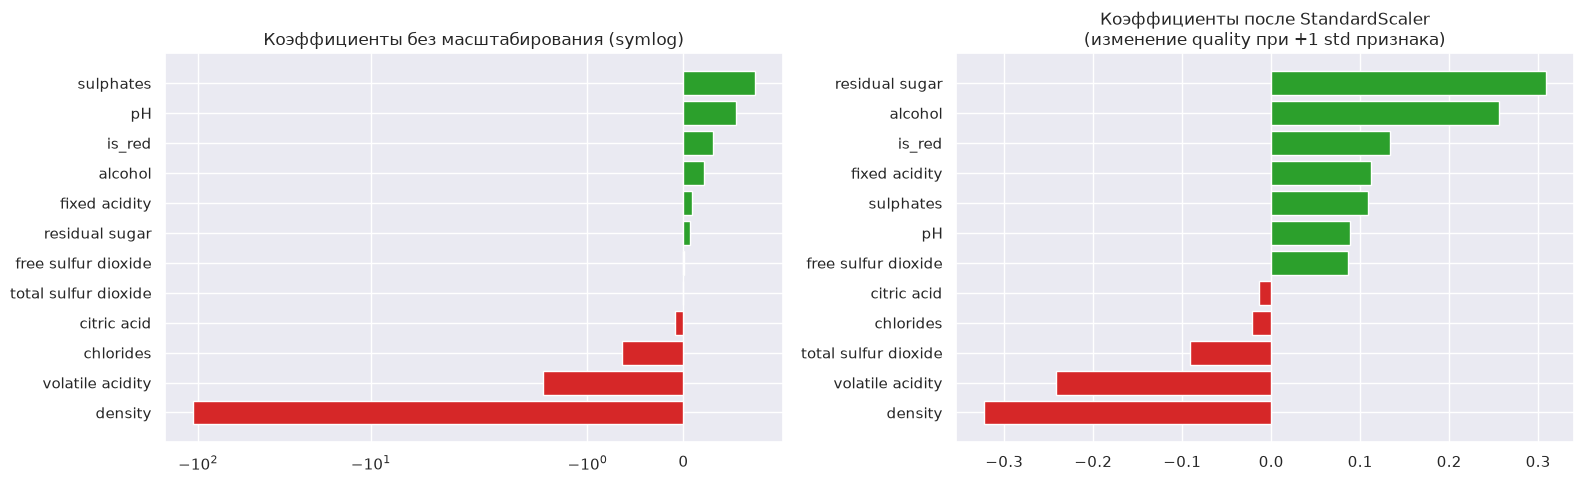

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
c_raw = coefs["coef_raw"].sort_values()
axs[0].barh(c_raw.index, c_raw.values, color=["tab:red" if v < 0 else "tab:green" for v in c_raw])
axs[0].set_xscale("symlog"); axs[0].set_title("Коэффициенты без масштабирования (symlog)")
c_sc = coefs["coef_scaled"].sort_values()
axs[1].barh(c_sc.index, c_sc.values, color=["tab:red" if v < 0 else "tab:green" for v in c_sc])
axs[1].set_title("Коэффициенты после StandardScaler\n(изменение quality при +1 std признака)")
plt.tight_layout()

In [17]:
# Устойчивость коэффициентов: Ridge с подбором alpha по CV и модель без density
ridge = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("model", Ridge())]),
    {"model__alpha": np.logspace(-3, 3, 25)},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
).fit(X_train, y_train)
print("Ridge: best alpha = %.3f, CV RMSE = %.4f" % (ridge.best_params_["model__alpha"], -ridge.best_score_))

no_density = [f for f in FEATURES if f != "density"]
lr_nd = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
nd_score = -cross_val_score(lr_nd, X_train[no_density], y_train, cv=cv, scoring="neg_root_mean_squared_error").mean()
print("LinearRegression без density: CV RMSE = %.4f" % nd_score)
lr_nd.fit(X_train[no_density], y_train)
pd.DataFrame({
    "с density": coefs["coef_scaled"],
    "без density": pd.Series(lr_nd.named_steps["model"].coef_, index=no_density),
}).sort_values("с density", key=abs, ascending=False)

Ridge: best alpha = 17.783, CV RMSE = 0.7376
LinearRegression без density: CV RMSE = 0.7407


,с density,без density
density,-0.3230,NaN
residual sugar,0.3086,0.1109
alcohol,0.2558,0.3931
volatile acidity,-0.2423,-0.2548
is_red,0.1335,0.0364
fixed acidity,0.1121,-0.0038
sulphates,0.1093,0.0886
total sulfur dioxide,-0.0909,-0.1115
pH,0.0881,0.0204
free sulfur dioxide,0.0861,0.0993


**Анализ линейной регрессии:**

- RMSE на тесте ≈ 0.73 против 0.87 у baseline: модель **извлекает полезную информацию** из признаков (ошибка ниже на ~17%), но **порог 0.70 не проходит**. Train RMSE и CV RMSE почти совпадают с тестом, то есть переобучения нет: модель **недообучена**, её ограничивает линейная форма. Ridge с подобранным alpha даёт практически то же качество, значит, дело не в регуляризации, а в выразительности модели.
- **Немасштабированные коэффициенты вводят в заблуждение:** у `density` коэффициент порядка десятков-сотен (по модулю), просто потому что её стандартное отклонение ~0.003. Если сравнивать «сырые» коэффициенты, density кажется самым важным признаком, а `total sulfur dioxide` — бесполезным. Это артефакт единиц измерения.
- **После стандартизации** самые влиятельные признаки: `density` (−0.32), `residual sugar` (+0.31), `alcohol` (+0.26), `volatile acidity` (−0.24), далее `is_red`, `fixed acidity`, `sulphates`. Немасштабированный коэффициент density ≈ −107, а после стандартизации он того же порядка, что у остальных признаков.
- **Осторожно с density и residual sugar.** Их большие стандартизированные коэффициенты противоречат EDA (residual sugar почти не коррелирует с quality). Это эффект **мультиколлинеарности**: density ≈ f(alcohol, sugar), и модель использует их комбинацию. Положительный вес сахара «компенсирует» сахарную составляющую плотности. Если убрать density, CV RMSE почти не меняется (0.738 → 0.741), вес сахара падает с 0.31 до 0.11, а вес alcohol растёт с 0.26 до 0.39. Значит, коэффициенты коррелированных признаков интерпретировать по отдельности нельзя.
- **Устойчивые выводы**, согласованные с EDA: больше алкоголя → выше оценка; больше летучей кислотности → ниже оценка; больше сульфатов → немного выше.

## 5.2 Random Forest Regressor

Случайный лес — бэггинг глубоких деревьев. Он улавливает нелинейности и взаимодействия признаков (например, «тип вина × кислотность»), устойчив к выбросам и не требует масштабирования.
Подберём гиперпараметры по **кросс-валидации на train** (тест не трогаем).

In [18]:
rf_search = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    {"max_features": [0.33, 0.5, 1.0], "min_samples_leaf": [1, 2, 4]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=1,
).fit(X_train, y_train)
print("Лучшие параметры:", rf_search.best_params_, " CV RMSE = %.4f" % -rf_search.best_score_)
pd.DataFrame(rf_search.cv_results_)[["param_max_features", "param_min_samples_leaf", "mean_test_score"]] \
    .assign(cv_rmse=lambda d: -d.mean_test_score).drop(columns="mean_test_score").sort_values("cv_rmse")

Лучшие параметры: {'max_features': 0.33, 'min_samples_leaf': 1}  CV RMSE = 0.6130


,param_max_features,param_min_samples_leaf,cv_rmse
0,0.33,1,0.6130
3,0.50,1,0.6162
4,0.50,2,0.6229
6,1.00,1,0.6236
1,0.33,2,0.6246
7,1.00,2,0.6276
5,0.50,4,0.6375
8,1.00,4,0.6391
2,0.33,4,0.6419


In [19]:
rf = RandomForestRegressor(n_estimators=1000, random_state=RANDOM_STATE, n_jobs=-1, **rf_search.best_params_)
rf.fit(X_train, y_train)
print("Train RMSE = %.4f" % root_mean_squared_error(y_train, rf.predict(X_train)))
evaluate("Random Forest", rf.predict(X_test))

Train RMSE = 0.2196
Random Forest: RMSE = 0.5920, MAE = 0.4230


alcohol                 0.1770
volatile acidity        0.1104
density                 0.1074
free sulfur dioxide     0.0846
chlorides               0.0824
total sulfur dioxide    0.0791
residual sugar          0.0755
sulphates               0.0739
citric acid             0.0720
pH                      0.0694
fixed acidity           0.0640
is_red                  0.0043
dtype: float64

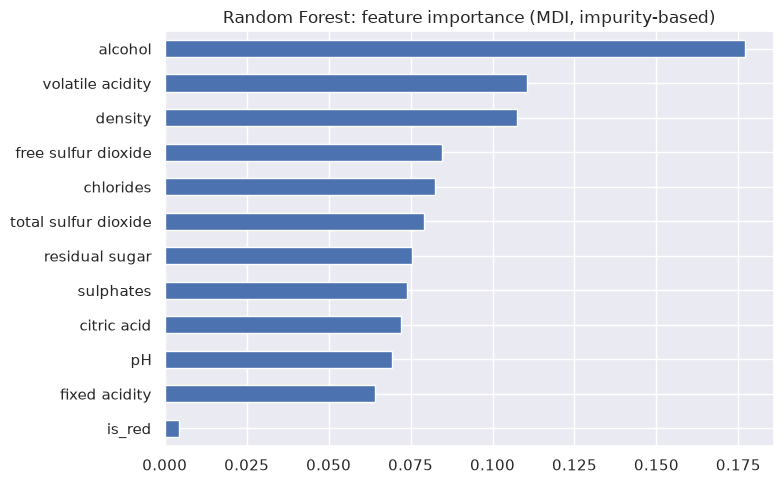

In [20]:
rf_imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
rf_imp.plot.barh(figsize=(8, 5), title="Random Forest: feature importance (MDI, impurity-based)")
plt.tight_layout()
rf_imp.sort_values(ascending=False)

**Random Forest:** тестовый RMSE ≈ 0.59 (CV ≈ 0.61) — **порог 0.70 пройден** с запасом, и лес гораздо лучше линейной регрессии. Train RMSE (≈0.22) намного ниже тестового: глубокие деревья почти запоминают обучающую выборку, но усреднение сотен деревьев сохраняет обобщающую способность.

**Важные признаки (MDI):** на первом месте `alcohol`, далее `volatile acidity`, `density`, `free sulfur dioxide`. Это согласуется с EDA: alcohol и volatile acidity — два самых информативных признака по корреляциям. Отличия от линейной регрессии:
- `free sulfur dioxide` у леса заметно важнее, чем у линейной модели. Его связь с качеством немонотонная: и слишком мало (риск окисления), и слишком много SO₂ плохо, а линейная модель такую «горбатую» зависимость уловить не может.
- `residual sugar` у леса умеренно важен, а у линейной модели огромный вес возникал из-за компенсации density.
- `density` получает высокую важность в основном как «заместитель» alcohol: MDI делит важность между коррелированными признаками.
- `is_red` почти не важен: тип вина однозначно восстанавливается из других признаков (total SO₂, chlorides, volatile acidity), и деревья используют их.

## 5.3 Gradient Boosting Regressor

Градиентный бустинг строит неглубокие деревья последовательно, и каждое следующее исправляет ошибки предыдущих. Сначала посмотрим на модель с параметрами по умолчанию, затем подберём гиперпараметры по CV на train.

In [21]:
gb_default = GradientBoostingRegressor(random_state=RANDOM_STATE)
print("GB (default: 100 деревьев, depth=3, lr=0.1) CV RMSE = %.4f ± %.4f" % cv_rmse(gb_default))

GB (default: 100 деревьев, depth=3, lr=0.1) CV RMSE = 0.6886 ± 0.0121


In [22]:
gb_search = GridSearchCV(
    GradientBoostingRegressor(n_estimators=800, learning_rate=0.05, subsample=0.8, random_state=RANDOM_STATE),
    {"max_depth": [4, 6, 8], "min_samples_leaf": [1, 5]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
).fit(X_train, y_train)
print("Лучшие параметры:", gb_search.best_params_, " CV RMSE = %.4f" % -gb_search.best_score_)
pd.DataFrame(gb_search.cv_results_)[["param_max_depth", "param_min_samples_leaf", "mean_test_score"]] \
    .assign(cv_rmse=lambda d: -d.mean_test_score).drop(columns="mean_test_score").sort_values("cv_rmse")

Лучшие параметры: {'max_depth': 8, 'min_samples_leaf': 5}  CV RMSE = 0.6226


,param_max_depth,param_min_samples_leaf,cv_rmse
5,8,5,0.6226
4,8,1,0.6253
2,6,1,0.6283
3,6,5,0.6309
0,4,1,0.6505
1,4,5,0.6529


In [23]:
gb = gb_search.best_estimator_
print("Train RMSE = %.4f" % root_mean_squared_error(y_train, gb.predict(X_train)))
evaluate("Gradient Boosting", gb.predict(X_test))

Train RMSE = 0.0410
Gradient Boosting: RMSE = 0.5920, MAE = 0.3937


,Random Forest,Gradient Boosting
alcohol,0.1770,0.2193
volatile acidity,0.1104,0.1270
density,0.1074,0.0690
free sulfur dioxide,0.0846,0.0885
chlorides,0.0824,0.0686
total sulfur dioxide,0.0791,0.0807
residual sugar,0.0755,0.0766
sulphates,0.0739,0.0777
citric acid,0.0720,0.0620
pH,0.0694,0.0694


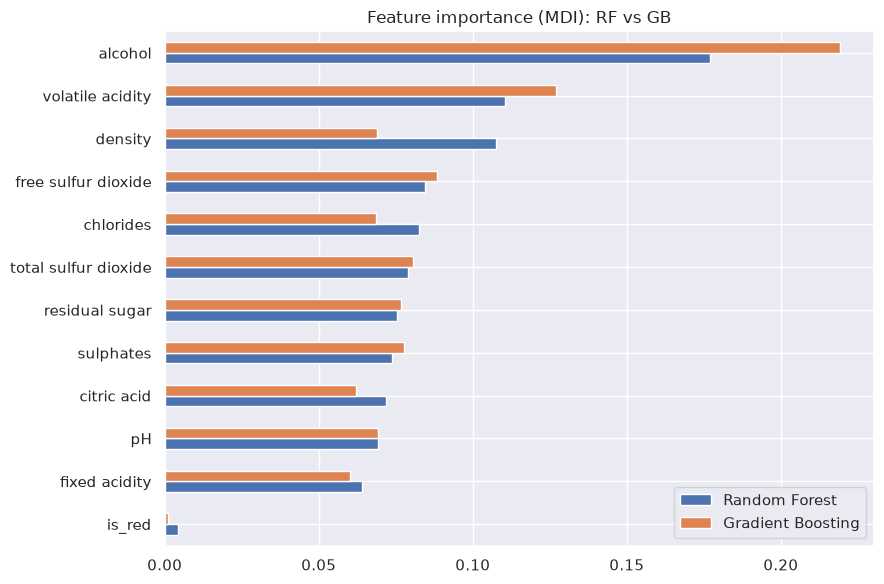

In [24]:
gb_imp = pd.Series(gb.feature_importances_, index=FEATURES)
imp = pd.DataFrame({"Random Forest": rf_imp, "Gradient Boosting": gb_imp}).sort_values("Random Forest")
imp.plot.barh(figsize=(9, 6), title="Feature importance (MDI): RF vs GB")
plt.tight_layout()
imp.sort_values("Random Forest", ascending=False)

**Gradient Boosting:**
- Бустинг с параметрами по умолчанию (100 деревьев глубины 3) даёт CV RMSE ≈ 0.69, то есть заметно хуже леса: такие неглубокие деревья недостаточно выразительны для этих данных. После подбора по CV (глубина 8, 800 итераций с шагом 0.05, subsample 0.8) бустинг почти догнал лес: на CV он чуть хуже (0.623 vs 0.612), на тесте RMSE одинаковый (0.592), а MAE даже лучше (0.394 vs 0.423). Train RMSE бустинга ≈ 0.04, то есть он практически запомнил обучающую выборку, но благодаря малому шагу и subsample всё равно хорошо обобщает.
- **Важность признаков у RF и GB похожа**: в обоих лидирует `alcohol`, затем `volatile acidity` и `free sulfur dioxide`. У бустинга важность чуть сильнее сконцентрирована на `alcohol`, потому что первые деревья «забирают» на него самую крупную часть сигнала. Лес из-за случайного выбора признаков в каждом сплите (`max_features`) распределяет важность более равномерно, особенно между коррелированными `alcohol` и `density`.

# 6. Честное сравнение моделей

Все модели обучены на **одном и том же train**, гиперпараметры подбирались **только по CV на train**, оценка — на **одном и том же test** (одно и то же разбиение с `random_state=42`).

In [25]:
cv_table = {
    "Baseline (mean)": np.nan,
    "Linear Regression": cv_rmse(lr_pipeline)[0],
    "Random Forest": cv_rmse(rf)[0],
    "Gradient Boosting": cv_rmse(gb)[0],
}
summary = pd.DataFrame(results).T
summary["CV RMSE (train)"] = pd.Series(cv_table)
summary["RMSE / MAE"] = summary["RMSE"] / summary["MAE"]
summary["улучшение RMSE vs baseline"] = 1 - summary["RMSE"] / summary.loc["Baseline (mean)", "RMSE"]
summary["RMSE < 0.70"] = summary["RMSE"] < 0.70
summary.index.name = "Модель"
summary

,RMSE,MAE,CV RMSE (train),RMSE / MAE,улучшение RMSE vs baseline,RMSE < 0.70
Модель,,,,,,
Baseline (mean),0.8738,0.6861,NaN,1.2736,0.0000,False
Linear Regression,0.7280,0.5678,0.7377,1.2821,0.1669,False
Random Forest,0.5920,0.4230,0.6123,1.3995,0.3225,True
Gradient Boosting,0.5920,0.3937,0.6226,1.5038,0.3224,True


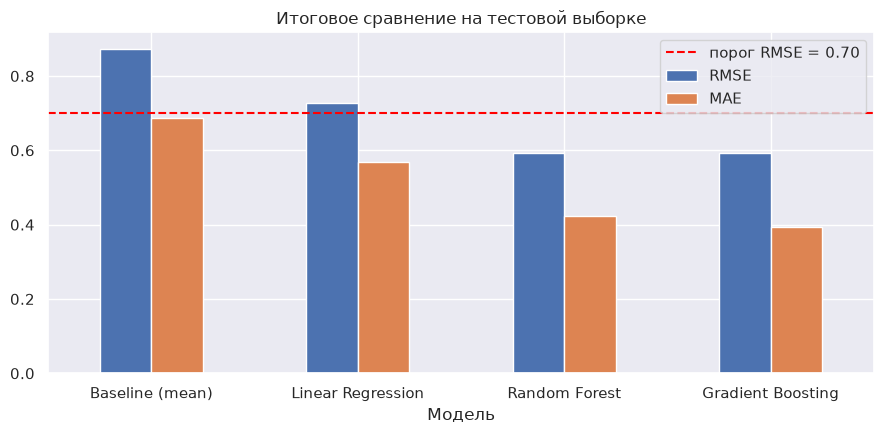

In [26]:
ax = summary[["RMSE", "MAE"]].plot.bar(figsize=(9, 4.5), rot=0)
ax.axhline(0.70, color="red", ls="--", label="порог RMSE = 0.70")
ax.legend(); ax.set_title("Итоговое сравнение на тестовой выборке")
plt.tight_layout()

**Выводы по сравнению:**

- **Все три модели превзошли baseline**, то есть действительно извлекают из признаков полезную информацию. Порог RMSE < 0.70 проходят только ансамбли деревьев. Линейная регрессия улучшает baseline, но остаётся выше порога.
- CV RMSE на train и RMSE на test близки для всех моделей, поэтому ранжирование устойчиво, а не случайно для конкретного разбиения.

**Почему ансамбли деревьев сильно лучше линейной регрессии:**
1. *Нелинейные связи.* Зависимость quality от alcohol нелинейна (у оценок 3–5 алкоголь почти одинаков, дальше резкий рост), а от `free sulfur dioxide` вообще немонотонна. Линейная модель описывает каждую такую связь одним наклоном.
2. *Взаимодействия.* Влияние признаков зависит от типа вина (sulphates и volatile acidity важны в основном для красных) и от сочетаний признаков. Линейная модель без ручного feature engineering учитывает только аддитивные эффекты.
3. *Выбросы и скошенные распределения* (chlorides, sugar, SO₂) сильно влияют на МНК, а деревьям, которые работают с порогами, неважен монотонный масштаб признака.
4. *Мультиколлинеарность* (density–alcohol–sugar) делает линейную модель неустойчивой, а для деревьев это не проблема.

**RF vs GB:** результаты близки. Лес строит глубокие деревья независимо и усредняет их, снижая дисперсию; он хорошо работает «из коробки» и мало чувствителен к гиперпараметрам. Бустинг последовательно уменьшает смещение и после настройки (глубина, шаг, subsample) достигает того же уровня, а без настройки (depth=3, 100 деревьев) заметно уступает. Здесь сигнал в данных слабый и шумный (оценки экспертов субъективны, это медиана как минимум трёх оценок), поэтому у обоих ансамблей есть «потолок»: часть разброса quality просто не объясняется физико-химией. Также вероятно, что глубоким деревьям в обоих ансамблях помогают дубликаты: одинаковые вина могут оказаться и в train, и в test.

**Отношение RMSE/MAE:** у baseline и линейной регрессии ≈ 1.28, у RF ≈ 1.40, у GB ≈ 1.50. Ансамбли сильно уменьшили типичные ошибки на массовых классах 5–7 (MAE упала сильнее, чем RMSE), а крупные промахи на редких винах остались. Поэтому хвосты ошибок стали относительно «тяжелее». У GB это выражено сильнее всего: при той же RMSE, что у леса, он точнее на типичных винах, но чаще грубо ошибается на редких (подробнее в анализе ошибок).

# 7. Feature importance

Встроенная важность MDI (impurity-based) у деревьев имеет известные недостатки: она считается на train, завышает важность признаков с большим числом уникальных значений и делит важность между коррелированными признаками. Поэтому дополнительно посчитаем **permutation importance на тестовой выборке**: насколько вырастает RMSE, если случайно перемешать значения признака. Это модельно-независимый способ, поэтому его можно применить и к линейной регрессии и сравнить все три модели в одной шкале.

,Linear Regression,Random Forest,Gradient Boosting
alcohol,0.0904,0.1766,0.1686
volatile acidity,0.0683,0.0844,0.0868
free sulfur dioxide,0.0103,0.0695,0.0994
density,0.1184,0.0524,0.0488
sulphates,0.0211,0.0510,0.0679
total sulfur dioxide,0.0123,0.0440,0.0661
chlorides,0.0002,0.0386,0.0286
citric acid,-0.0002,0.0376,0.0300
residual sugar,0.1089,0.0373,0.0574
pH,0.0091,0.0248,0.0294


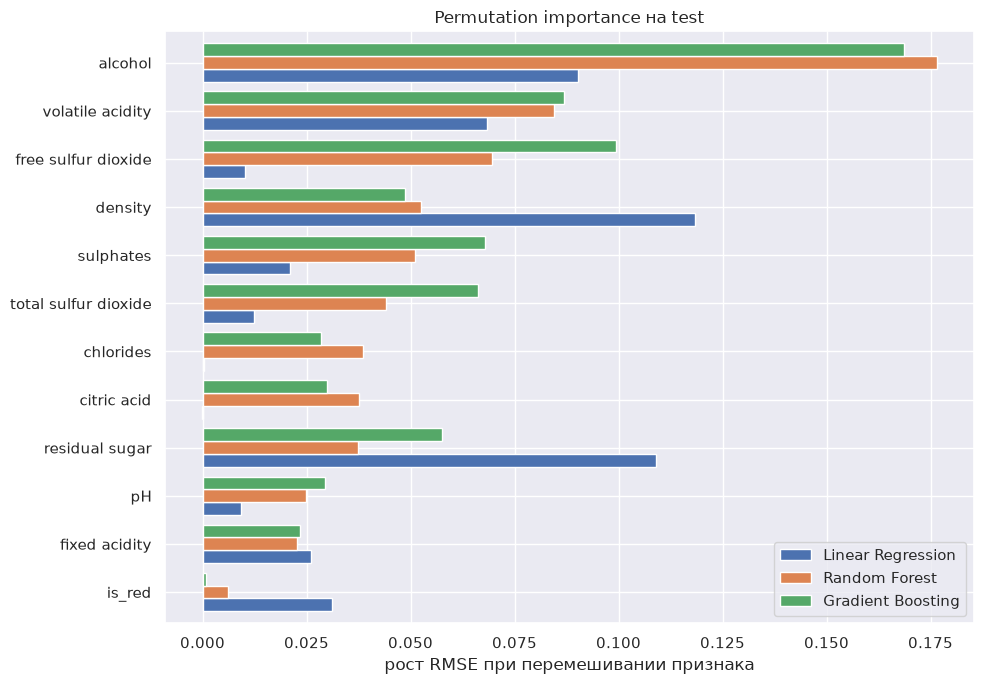

In [27]:
perm = {}
for name, model in [("Linear Regression", lr_pipeline), ("Random Forest", rf), ("Gradient Boosting", gb)]:
    r = permutation_importance(model, X_test, y_test, n_repeats=15, random_state=RANDOM_STATE,
                               scoring="neg_root_mean_squared_error", n_jobs=-1)
    perm[name] = pd.Series(r.importances_mean, index=FEATURES)
perm = pd.DataFrame(perm)

order = perm["Random Forest"].sort_values().index
perm.loc[order].plot.barh(figsize=(10, 7), width=0.8)
plt.xlabel("рост RMSE при перемешивании признака")
plt.title("Permutation importance на test")
plt.tight_layout()
perm.loc[order[::-1]]

In [28]:
# Сводная таблица рангов важности (1 = самый важный)
ranks = pd.DataFrame({
    "|corr| с quality (EDA)": target_corr.abs().rank(ascending=False),
    "|coef| LR (scaled)": coefs["coef_scaled"].abs().rank(ascending=False),
    "RF MDI": rf_imp.rank(ascending=False),
    "GB MDI": gb_imp.rank(ascending=False),
    "RF permutation": perm["Random Forest"].rank(ascending=False),
    "GB permutation": perm["Gradient Boosting"].rank(ascending=False),
}).astype(int).sort_values("RF permutation")
ranks

,|corr| с quality (EDA),|coef| LR (scaled),RF MDI,GB MDI,RF permutation,GB permutation
alcohol,1,3,1,1,1,1
volatile acidity,3,4,2,2,2,3
free sulfur dioxide,8,10,4,3,3,2
density,2,1,3,8,4,7
sulphates,10,7,8,5,5,4
total sulfur dioxide,9,8,6,4,6,5
chlorides,4,11,5,9,7,10
citric acid,6,12,9,10,8,8
residual sugar,11,2,7,6,9,6
pH,12,9,10,7,10,9


**Выводы по важности признаков:**

1. **`alcohol` — безусловно главный признак** во всех методах: первое место по корреляции в EDA, наибольший стандартизированный коэффициент LR, первое место по MDI и по permutation importance у обоих ансамблей.
2. **`volatile acidity`** стабильно входит в топ-3 у всех моделей, как и предсказывал EDA.
3. **`free sulfur dioxide`** важен для деревьев (топ-3–4 по permutation), хотя линейная корреляция с quality около нуля. Связь немонотонная, и её видят только нелинейные модели. Это пример того, как корреляционный анализ может недооценить признак.
4. **`density`**: у RF по MDI 3-е место, у GB по permutation только 7-е. Это классический эффект коррелированных признаков: при перемешивании density модель «достаёт» ту же информацию из alcohol и residual sugar. У линейной регрессии permutation importance density и residual sugar — самые высокие (выше даже alcohol), потому что модель построена на компенсации density ↔ alcohol/sugar, и перемешивание одного из них ломает её.
5. **`is_red`** почти не важен ни для одной модели: тип вина восстанавливается по химическому составу.
6. **`sulphates` и `total sulfur dioxide`** у деревьев на 4–6 местах, хотя на всём датасете |r| < 0.05. Для sulphates это объясняется EDA: у красных вин r ≈ 0.25, у белых почти 0, и деревья используют эту условную зависимость.
7. Наименее важны `fixed acidity`, `pH`, `citric acid`, `chlorides`.

RF и GB согласуются между собой гораздо лучше, чем каждый из них с линейной регрессией, что ожидаемо для двух ансамблей деревьев.

**Можно ли на основании feature importance утверждать, что изменение признака *является причиной* изменения качества вина? — Нет.**
- Feature importance показывает, насколько **модель использует** признак для предсказания, то есть это мера *ассоциации в данных*, а не причинно-следственной связи. Модель учится на наблюдательных данных, а не на эксперименте, где меняют один признак при прочих равных.
- **Конфаундеры:** высокий alcohol может быть следствием спелого, качественного винограда, хорошего года и технологии производства. Эти факторы одновременно повышают и алкоголь, и качество. Если просто добавить спирт в плохое вино, оно не станет лучше.
- **Коррелированные признаки:** важность «переливается» между density и alcohol. density важна для модели, но менять плотность вина ради качества бессмысленно, это лишь прокси для алкоголя и сахара.
- Важность зависит от модели и метода (MDI vs permutation дают разные ранги), а не только от данных.
- Для причинных выводов нужны контролируемые эксперименты или методы causal inference. Feature importance помогает только сформулировать гипотезы.

# 8. Анализ ошибок лучшей модели

Лучшую модель выбираем **по CV RMSE на train** (не по тесту), а затем анализируем её ошибки на тестовой выборке.

In [29]:
best_name = summary["CV RMSE (train)"].idxmin()
best_model = {"Linear Regression": lr_pipeline, "Random Forest": rf, "Gradient Boosting": gb}[best_name]
print("Лучшая модель по CV:", best_name)

err = X_test.copy()
err["quality"] = y_test
err["pred"] = best_model.predict(X_test)
err["error"] = err["pred"] - err["quality"]          # >0 — переоценили, <0 — недооценили
err["abs_error"] = err["error"].abs()
err["error"].describe()

Лучшая модель по CV: Random Forest


count    1300.0000
mean        0.0383
std         0.5910
min        -2.3850
25%        -0.2602
50%         0.0305
75%         0.3283
max         2.6110
Name: error, dtype: float64

Доля ошибок |e| < 0.5: 0.686
Доля ошибок |e| < 1.0: 0.902
Доля верных после округления: 0.686


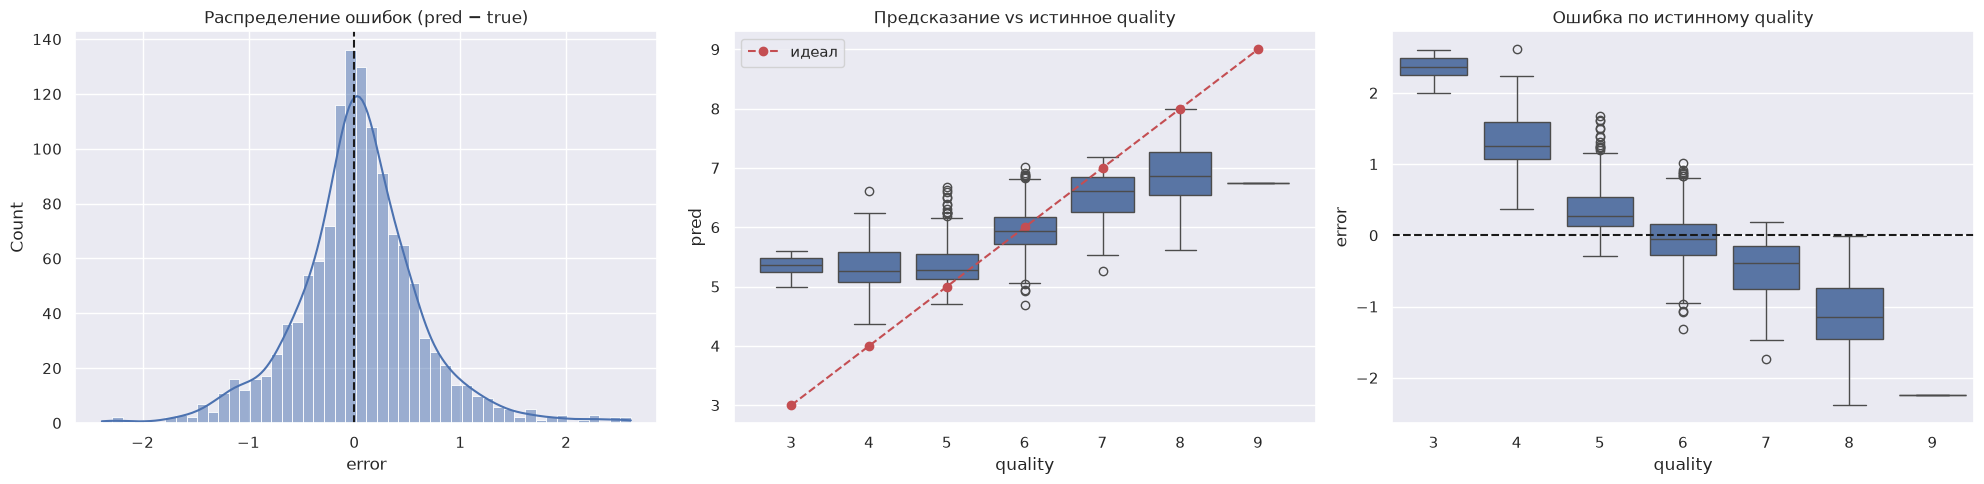

In [30]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
sns.histplot(err["error"], bins=50, kde=True, ax=axs[0])
axs[0].axvline(0, color="k", ls="--"); axs[0].set_title("Распределение ошибок (pred − true)")

sns.boxplot(data=err, x="quality", y="pred", ax=axs[1])
axs[1].plot(range(err["quality"].nunique()), sorted(err["quality"].unique()), "r--o", label="идеал")
axs[1].legend(); axs[1].set_title("Предсказание vs истинное quality")

sns.boxplot(data=err, x="quality", y="error", ax=axs[2])
axs[2].axhline(0, color="k", ls="--"); axs[2].set_title("Ошибка по истинному quality")
plt.tight_layout()

print("Доля ошибок |e| < 0.5:", (err["abs_error"] < 0.5).mean().round(3))
print("Доля ошибок |e| < 1.0:", (err["abs_error"] < 1.0).mean().round(3))
print("Доля верных после округления:", (err["pred"].round() == err["quality"]).mean().round(3))

In [31]:
by_q = err.groupby("quality").agg(
    n=("error", "size"),
    mean_pred=("pred", "mean"),
    bias=("error", "mean"),
    MAE=("abs_error", "mean"),
    RMSE=("error", lambda e: np.sqrt(np.mean(e ** 2))),
)
by_q["доля в train"] = y_train.value_counts(normalize=True).reindex(by_q.index).round(4)
by_q

,n,mean_pred,bias,MAE,RMSE,доля в train
quality,,,,,,
3,6,5.3433,2.3433,2.3433,2.3516,0.0046
4,43,5.3204,1.3204,1.3204,1.3968,0.0333
5,428,5.3761,0.3761,0.3849,0.5043,0.3290
6,567,5.9421,-0.0579,0.2900,0.3766,0.4366
7,216,6.5172,-0.4828,0.4860,0.6254,0.1661
8,39,6.9059,-1.0941,1.0941,1.2378,0.0296
9,1,6.7520,-2.2480,2.2480,2.2480,0.0008


In [32]:
# Объекты с наибольшими ошибками
worst = err.sort_values("abs_error", ascending=False).head(10)
worst[["is_red", "alcohol", "volatile acidity", "free sulfur dioxide", "sulphates", "density",
       "residual sugar", "quality", "pred", "error"]]

,is_red,alcohol,volatile acidity,free sulfur dioxide,sulphates,density,residual sugar,quality,pred,error
6107,0,11.5,0.260,75.0,0.38,0.9902,2.60,4,6.611,2.611
2339,0,12.6,0.390,5.0,0.37,0.9915,4.60,3,5.601,2.601
3287,0,9.4,0.250,118.5,0.63,0.9949,1.55,3,5.496,2.496
1850,0,9.8,0.260,41.0,0.50,0.9980,16.20,3,5.438,2.438
3005,0,10.5,0.220,12.0,0.38,0.9944,6.80,8,5.615,-2.385
1374,1,9.8,0.815,16.0,0.51,0.9947,1.20,3,5.300,2.300
2426,0,12.5,0.240,27.0,0.48,0.9906,2.00,9,6.752,-2.248
5369,0,12.0,0.270,15.0,0.65,0.9909,2.40,4,6.232,2.232
1403,1,10.0,0.330,3.0,1.10,0.9960,1.70,8,5.770,-2.230
1469,1,9.7,0.980,20.0,0.55,0.9970,2.10,3,5.226,2.226


In [33]:
# Сравним самые грубые ошибки с «типичным» вином той же истинной оценки и того же типа в train
train_full = X_train.assign(quality=y_train)
key = ["alcohol", "volatile acidity", "free sulfur dioxide", "sulphates", "residual sugar", "chlorides"]
rows = []
for idx, r in worst.head(5).iterrows():
    same = train_full[(train_full.quality == r.quality) & (train_full.is_red == r.is_red)]
    pred_cls = train_full[(train_full.quality == round(r.pred)) & (train_full.is_red == r.is_red)]
    rows.append(pd.concat([
        r[key].rename(f"объект {idx} (true={r.quality}, pred={r.pred:.2f})"),
        same[key].median().rename(f"  медиана train: quality={r.quality}, n={len(same)}"),
        pred_cls[key].median().rename(f"  медиана train: quality={round(r.pred)}"),
    ], axis=1).T)
pd.concat(rows)

,alcohol,volatile acidity,free sulfur dioxide,sulphates,residual sugar,chlorides
"объект 6107 (true=4.0, pred=6.61)",11.50,0.26,75.0,0.380,2.60,0.034
"медиана train: quality=4.0, n=131",10.00,0.33,18.0,0.470,3.00,0.047
медиана train: quality=7,11.35,0.25,33.0,0.480,3.55,0.037
"объект 2339 (true=3.0, pred=5.60)",12.60,0.39,5.0,0.370,4.60,0.022
"медиана train: quality=3.0, n=16",10.50,0.26,33.5,0.435,4.30,0.041
медиана train: quality=6,10.40,0.25,34.0,0.480,5.50,0.043
"объект 3287 (true=3.0, pred=5.50)",9.40,0.25,118.5,0.630,1.55,0.041
"медиана train: quality=3.0, n=16",10.50,0.26,33.5,0.435,4.30,0.041
медиана train: quality=5,9.50,0.28,35.0,0.470,7.10,0.047
"объект 1850 (true=3.0, pred=5.44)",9.80,0.26,41.0,0.500,16.20,0.074


In [34]:
# Есть ли у грубо ошибочных объектов «двойники» в train с другой оценкой?
dup_cols = FEATURES
merged = worst.reset_index().merge(train_full, on=dup_cols, how="left", suffixes=("", "_train"))
merged[["index", "quality", "pred", "quality_train"]].dropna()

,index,quality,pred,quality_train


**Выводы по анализу ошибок:**

- **Распределение ошибок** близко к симметричному с центром около нуля (средняя ошибка ≈ +0.04) и тяжёлыми хвостами. 69% предсказаний ошибаются меньше чем на 0.5 балла, 90% — меньше чем на 1 балл, но есть ошибки до 2.6 балла. Именно они дают разрыв между RMSE и MAE.
- **Качество сильно зависит от истинного quality.** Для самого массового класса 6 RMSE ≈ 0.38 и смещение ≈ 0, для класса 5 RMSE ≈ 0.50. Для крайних классов у модели **систематическое смещение к центру**: вина с оценкой 3 в среднем получают 5.34 (bias +2.3), с оценкой 4 — 5.32 (bias +1.3), с оценкой 8 — 6.91 (bias −1.1), единственное вино с оценкой 9 — 6.75. Модель практически никогда не предсказывает ниже 5 и выше 7: предсказания «сплющены» к центру. Это регрессия к среднему.
- **Объекты с наибольшими ошибками** — в основном редкие классы (3, 4, 8):
  - *Объект 6107* (белое, true = 4, pred = 6.6): alcohol 11.5 и volatile acidity 0.26, что ближе к медиане вин с оценкой 7 (11.35 и 0.25), чем к винам с оценкой 4 (10.0 и 0.33). Химически это «хорошее» вино, и модель ставит ему высокую оценку.
  - *Объект 2339* (белое, true = 3, pred = 5.6): alcohol 12.6, сильно выше медианы класса 3 (10.5). Единственный «тревожный» сигнал — очень мало свободного SO₂ (5 против ~34 у типичного вина), что может означать окисление. Но таких примеров с оценкой 3 в train почти нет (всего 16 белых вин с оценкой 3), и модель не может выучить это правило.
  - *Объект 3005* (белое, true = 8, pred = 5.6): alcohol 10.5 и низкий free SO₂. По признакам это типичное вино класса 6, и чем оно понравилось экспертам, по этим 11 признакам не видно.
  - *Объекты 3287 и 1850* (true = 3) имеют необычные значения (free SO₂ = 118.5, residual sugar = 16.2), но по ключевым alcohol/volatile acidity похожи на средние вина класса 5. Таких аномалий в train слишком мало, чтобы модель научилась считать их признаком плохого вина.

  У таких объектов ключевые признаки ближе к типичным винам *предсказанного* класса, чем истинного, то есть по имеющимся признакам они почти неотличимы от средних. Возможные причины: оценку определили факторы, которых нет в данных (аромат, сорт винограда, выдержка, бренд — по описанию датасета эта информация скрыта), субъективность экспертов или ошибки разметки. Точных «двойников» этих объектов в train нет (последняя ячейка выше пустая), так что ошибки не вызваны противоречивыми дубликатами.

**Почему модель хуже предсказывает редкие значения quality:**
1. *Мало примеров:* оценок 3 и 9 в train единицы-десятки. Деревьям не хватает объектов, чтобы выделить для них отдельные листья, и в листьях они смешиваются с массой пятёрок и шестёрок.
2. *Минимизация MSE на несбалансированных данных:* средняя ошибка определяется массовыми классами, поэтому модели выгодно хорошо работать на 5–6 и «сжимать» предсказания к среднему. Листья деревьев и усреднение в лесе дают средние значения, которые физически тянутся к центру распределения.
3. *Перекрытие классов в пространстве признаков:* крайние классы химически не отделены от средних (EDA показал слабые корреляции, max |r| = 0.44), поэтому сигнал для них слабее шума.
4. *Оценка — медиана нескольких экспертов:* экстремальные значения медианы встречаются реже, и в них больше неопределённости.

Что можно улучшить: взвешивание редких классов (sample_weight), постобработку, растягивающую предсказания (калибровку), отдельные модели для красного и белого, ordinal-подходы. Но надо помнить, что любое из этих улучшений, скорее всего, немного ухудшит RMSE на массовых классах.

# 9. Итог

| Модель | RMSE (test) | MAE (test) |
|---|---|---|
| Baseline (mean) | 0.8738 | 0.6861 |
| Linear Regression | 0.7280 | 0.5678 |
| Random Forest | **0.5920** | 0.4230 |
| Gradient Boosting | **0.5920** | **0.3937** |

- Baseline (константа = среднее train) задаёт уровень RMSE ≈ 0.87.
- Линейная регрессия извлекает полезную информацию (≈ −17% RMSE), но упирается в линейность модели и не проходит порог 0.70.
- Random Forest и настроенный Gradient Boosting проходят порог с запасом (RMSE ≈ 0.59). Лучшая по CV модель — Random Forest, она же используется как финальная, потому что улавливают нелинейные зависимости, немонотонные эффекты (free SO₂) и взаимодействия признаков с типом вина.
- Ключевые признаки во всех моделях — `alcohol` и `volatile acidity`; для деревьев важен также `free sulfur dioxide`. Важность признаков — это ассоциация, а не причинность.
- Основной источник ошибок — редкие крайние оценки (3–4 и 8–9), которые модель систематически сдвигает к центру.

In [35]:
# Финальная модель для скрытой тестовой выборки: обучаем лучшую конфигурацию на всех доступных данных.
# Ожидаемый вход — DataFrame с 11 исходными признаками и признаком is_red (1 — красное, 0 — белое).
final_model = best_model.__class__(**best_model.get_params()).fit(X, y)

def predict_quality(data: pd.DataFrame) -> np.ndarray:
    data = data.copy()
    if "is_red" not in data.columns and "type" in data.columns:
        data["is_red"] = (data["type"].astype(str).str.lower() == "red").astype(int)
    return final_model.predict(data[FEATURES])

predict_quality(X_test.head())

array([6.949, 5.433, 5.252, 5.154, 6.259])